## 02 - Evaluation Framework & Baseline Policy
Penguncian hold-out serta penetapan metrik dan baseline policy tanpa modeling


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, train_test_split

In [2]:
ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "data" / "Kevin_Hillstrom_Dataset.csv").squeeze("columns")
df

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
63995,10,2) $100 - $200,105.54,1,0,Urban,0,Web,Mens E-Mail,0,0,0.0
63996,5,1) $0 - $100,38.91,0,1,Urban,1,Phone,Mens E-Mail,0,0,0.0
63997,6,1) $0 - $100,29.99,1,0,Urban,1,Phone,Mens E-Mail,0,0,0.0
63998,1,5) $500 - $750,552.94,1,0,Surburban,1,Multichannel,Womens E-Mail,0,0,0.0


## 1. Split: hold-out dikunci, dev dibagi 5 fold
- Stratifikasi berdasarkan arm x visit
- File disimpan di CSV berbeda

In [3]:
SEED = 42
ARM_COL, TARGET = "segment", "visit"
CTRL, TR1, TR2 = "No E-Mail", "Mens E-Mail", "Womens E-Mail"
HOLDOUT_FRAC, N_FOLDS, N_BOOT = 0.30, 5, 1000
SPLIT_FILE = "split_hillstrom.csv"

assert df.index.is_unique, "index df harus unik (dipakai sebagai id baris)"
_trapz = getattr(np, "trapezoid", None) or np.trapz

In [4]:
strat = df[ARM_COL] + "_" + df[TARGET].astype(str)

dev_idx, ho_idx = train_test_split(
    df.index, test_size=HOLDOUT_FRAC, stratify=strat, random_state=SEED)

split = pd.Series("dev", index=df.index, name="split")
split.loc[ho_idx] = "holdout"

fold = pd.Series(-1, index=df.index, name="fold")          # -1 = hold-out
skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
dev_rows = df.loc[dev_idx]
for f, (_, te) in enumerate(skf.split(dev_rows, strat.loc[dev_idx])):
    fold.loc[dev_rows.index[te]] = f

pd.concat([split, fold], axis=1).to_csv(ROOT / "data" / SPLIT_FILE, index=True)
dev = df.loc[split == "dev"].copy()
dev["fold"] = fold.loc[dev.index]

In [5]:
# Cek komposisi hold-out
print(pd.crosstab(split, df[ARM_COL], normalize="index").round(3))
print(df.groupby(split)[TARGET].agg(n="size", visit_rate="mean").round(4))
print(dev.groupby("fold")[TARGET].agg(n="size", visit_rate="mean").round(4))

segment  Mens E-Mail  No E-Mail  Womens E-Mail
split                                         
dev            0.333      0.333          0.334
holdout        0.333      0.333          0.334
             n  visit_rate
split                     
dev      44800      0.1468
holdout  19200      0.1468
         n  visit_rate
fold                  
0     8960      0.1468
1     8960      0.1468
2     8960      0.1468
3     8960      0.1468
4     8960      0.1469


## 2. Metrik utama: nilai kebijakan (policy value)  

- Mengukur visit rate dengan kebijakan kirim email (tidak kirim/ Mens/ Womens)
- Peluang tiap arm ≈ 1/3 (No E-Mail, Mens, Womens), jadi setiap baris yang cocok dengan pilihan kebijakan dibobot 1/p ≈ 3 untuk mewakili seluruh pelanggan.



In [6]:
def evaluate_policies(y, arm, actions, prop, n_boot=N_BOOT, seed=SEED):
    """actions: dict nama -> array arm pilihan kebijakan untuk tiap baris."""
    y = np.asarray(y, float)
    arm = np.asarray(arm, object)
    p = pd.Series(arm).map(prop).to_numpy(float)
    W = np.column_stack([(arm == np.asarray(a, object)) / p for a in actions.values()])
    n = len(y)

    def est(ix):
        w = W[ix]
        return (w * y[ix, None]).sum(0) / w.sum(0)

    rng = np.random.default_rng(seed)
    point = est(np.arange(n))
    boots = np.array([est(rng.integers(0, n, n)) for _ in range(n_boot)])
    return list(actions), point, boots


def summarize(names, point, boots, refs):
    out = pd.DataFrame({"value": point}, index=names)
    out["ci_low"], out["ci_high"] = np.percentile(boots, [2.5, 97.5], axis=0)
    for r in refs:
        k = names.index(r)
        d = boots - boots[:, [k]]
        tag = r[:2]
        out[f"vs_{tag}"] = point - point[k]
        out[f"vs_{tag}_low"], out[f"vs_{tag}_high"] = np.percentile(d, [2.5, 97.5], axis=0)
    return out

## 3. Baseline Policy (kebijakan tanpa model ML), dievaluasi di dev  
- P0 tidak kirim ke siapa pun
- P1 Mens ke semua
- P2 Womens ke semua
- P1b email acak Mens/Womens 50:50 (ini setara dengan treatment "biner": tipe email tidak dipilih)
- P3 tabel mens x womens: untuk tiap sel pilih arm terbaik. Tabel ini DIPELAJARI dari data,
  jadi harus di-cross-fit (belajar di 4 fold, dipakai di fold ke-5) supaya tidak menilai
  dengan data yang sama dengan yang membentuk aturannya.
Kebijakan konstan (P0-P2) tidak punya parameter, jadi tidak perlu cross-fit.

In [7]:
n = len(dev)
prop = dev[ARM_COL].value_counts(normalize=True).to_dict()    # peluang arm (~1/3 masing-masing)

policies = {
    "P0 tidak kirim": np.full(n, CTRL, dtype=object),
    "P1 Mens ke semua": np.full(n, TR1, dtype=object),
    "P2 Womens ke semua": np.full(n, TR2, dtype=object),
}

p3 = pd.Series(index=dev.index, dtype=object)
for f in range(N_FOLDS):
    tr, te = dev[dev["fold"] != f], dev[dev["fold"] == f]
    best = tr.groupby(["mens", "womens", ARM_COL])[TARGET].mean().unstack().idxmax(axis=1)
    cells = pd.MultiIndex.from_frame(te[["mens", "womens"]])
    p3.loc[te.index] = best.reindex(cells).to_numpy()
policies["P3 tabel mens x womens"] = p3.to_numpy()

names, point, boots = evaluate_policies(dev[TARGET], dev[ARM_COL], policies, prop)

# Turunan: email acak 50:50 = rata-rata P1 dan P2 (kebijakan acak bernilai rata-rata pilihannya)
i1, i2 = names.index("P1 Mens ke semua"), names.index("P2 Womens ke semua")
names.append("P1b email acak (50:50)")
point = np.append(point, 0.5 * point[i1] + 0.5 * point[i2])
boots = np.column_stack([boots, 0.5 * boots[:, i1] + 0.5 * boots[:, i2]])

res = summarize(names, point, boots, refs=["P0 tidak kirim", "P1 Mens ke semua"])
print(res.round(4))

# Sanity check: nilai kebijakan konstan harus sama dengan rata-rata visit per arm
arm_mean = dev.groupby(ARM_COL)[TARGET].mean()
assert np.isclose(point[0], arm_mean[CTRL]) and np.isclose(point[1], arm_mean[TR1]) \
    and np.isclose(point[2], arm_mean[TR2]), "estimator tidak cocok dengan rata-rata arm"
print("\nTabel arm P3 per sel (di seluruh dev, hanya untuk dilihat):")
print(dev.groupby(["mens", "womens", ARM_COL])[TARGET].mean().unstack().round(4))

                         value  ci_low  ci_high   vs_P0  vs_P0_low  \
P0 tidak kirim          0.1061  0.1011   0.1111  0.0000     0.0000   
P1 Mens ke semua        0.1828  0.1771   0.1889  0.0766     0.0690   
P2 Womens ke semua      0.1514  0.1456   0.1570  0.0453     0.0374   
P3 tabel mens x womens  0.1825  0.1765   0.1888  0.0763     0.0681   
P1b email acak (50:50)  0.1671  0.1628   0.1713  0.0610     0.0544   

                        vs_P0_high   vs_P1  vs_P1_low  vs_P1_high  
P0 tidak kirim              0.0000 -0.0766    -0.0843     -0.0690  
P1 Mens ke semua            0.0843  0.0000     0.0000      0.0000  
P2 Womens ke semua          0.0524 -0.0313    -0.0405     -0.0230  
P3 tabel mens x womens      0.0838 -0.0003    -0.0059      0.0043  
P1b email acak (50:50)      0.0671 -0.0157    -0.0203     -0.0115  

Tabel arm P3 per sel (di seluruh dev, hanya untuk dilihat):
segment      Mens E-Mail  No E-Mail  Womens E-Mail
mens womens                                       
0    1  

- Mens ke semua mengalahkan tidak kirim (+7,7 poin) dan Womens ke semua (+3,1 poin). Adapun Mens dibanding dengan personalisasi Mens x Womens (+0,003 poin).  

Adapun ringkasannya bisa ditinjau di tabel di bawah:

**Baseline kebijakan, dievaluasi di dev (policy value = visit rate, setup B)**

| Kebijakan | Visit rate | Selisih vs P1 [CI 95%] | Verdict |
|---|---|---|---|
| P0 tidak kirim | 0,1061 | -0,0766 [-0,0843; -0,0690] | Kalah |
| **P1 Mens ke semua** | **0,1828** | patokan | |
| P2 Womens ke semua | 0,1514 | -0,0313 [-0,0405; -0,0230] | Kalah |
| P3 tabel mens×womens (cross-fit) | 0,1825 | -0,0003 [-0,0059; +0,0043] | Belum terbukti |



## 4. Metrik kedua: kurva uplift (kirim vs tidak kirim)  
- Pengurutan pengaruh email terhadap visit rate, krusial jika ada keterbatasan budget


In [8]:
def uplift_gain(y, t, score, ks=np.linspace(0.05, 1.0, 20), seed=0):
    y = np.asarray(y, float)
    t = np.asarray(t, int)
    s = np.asarray(score, float)
    n = len(y)
    order = np.lexsort((np.random.default_rng(seed).random(n), -s))   # untuk skor kembar urutan diacak
    y, t = y[order], t[order]
    cy_t, cy_c = np.cumsum(y * t), np.cumsum(y * (1 - t))
    cn_t, cn_c = np.cumsum(t), np.cumsum(1 - t)
    i = np.ceil(ks * n).astype(int) - 1
    gain = (cy_t[i] / cn_t[i] - cy_c[i] / cn_c[i]) * ks
    area = _trapz(gain - ks * gain[-1], ks)
    return ks, gain, area


def area_with_ci(y, t, score, n_boot=300, seed=SEED):
    y, t, s = (np.asarray(a) for a in (y, t, score))
    area = uplift_gain(y, t, s)[2]
    rng = np.random.default_rng(seed)
    n = len(y)
    b = [uplift_gain(y[ix], t[ix], s[ix])[2]
         for ix in (rng.integers(0, n, n) for _ in range(n_boot))]
    return area, np.percentile(b, [2.5, 97.5])

In [9]:
n_cells = dev[["mens", "womens"]].drop_duplicates().shape[0] # secara teoritis banyaknya adalah 4, namun angka yang digunakan adalah angka yang muncul
print(f"jumlah sel: {n_cells}")

jumlah sel: 3


skor acak                    area = -0.0007   CI95 = [-0.0025, +0.0010]
skor 3 sel mens x womens     area = +0.0039   CI95 = [+0.0019, +0.0056]


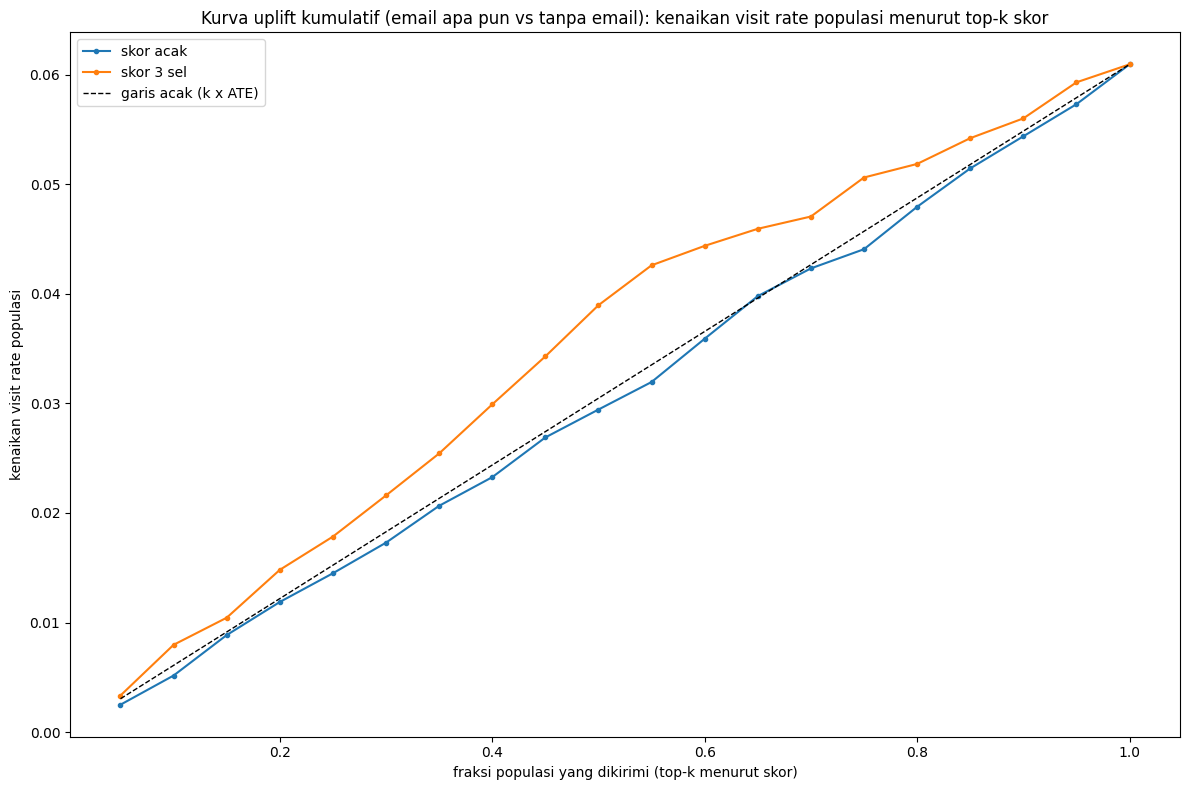

In [10]:
dev["treated"] = (dev[ARM_COL] != CTRL).astype(int)           # setup biner: any email vs control

score_rand = np.random.default_rng(SEED).random(n)             # pembanding: skor acak
score_cell = pd.Series(index=dev.index, dtype=float)           # skor 3 sel 3 sel didapat dari jumlah kombinasi mens womens yang ada di dev, cross-fit
for f in range(N_FOLDS):
    tr, te = dev[dev["fold"] != f], dev[dev["fold"] == f]
    g = tr.groupby(["mens", "womens", "treated"])[TARGET].mean().unstack("treated")
    cells = pd.MultiIndex.from_frame(te[["mens", "womens"]])
    score_cell.loc[te.index] = (g[1] - g[0]).reindex(cells).to_numpy()

for nm, sc in [("skor acak", score_rand), ("skor 3 sel mens x womens", score_cell.to_numpy())]:
    area, (lo, hi) = area_with_ci(dev[TARGET], dev["treated"], sc)
    print(f"{nm:28s} area = {area:+.4f}   CI95 = [{lo:+.4f}, {hi:+.4f}]")

fig, ax = plt.subplots(figsize=(12, 8))
for nm, sc in [("skor acak", score_rand), ("skor 3 sel", score_cell.to_numpy())]:
    ks, gain, _ = uplift_gain(dev[TARGET], dev["treated"], sc)
    ax.plot(ks, gain, marker="o", ms=3, label=nm)
ax.plot(ks, ks * gain[-1], "k--", lw=1, label="garis acak (k x ATE)")
ax.set_xlabel("fraksi populasi yang dikirimi (top-k menurut skor)")
ax.set_ylabel("kenaikan visit rate populasi")
ax.legend()
plt.title("Kurva uplift kumulatif (email apa pun vs tanpa email): kenaikan visit rate populasi menurut top-k skor")
plt.tight_layout()
plt.show()

Skor 3 sel mens × womens mengurutkan orang lebih baik dari acak: area +0,0039, CI95 tidak memuat 0. Skor acak lolos sanity check dengan area mendekati 0.

| Skor | Area | CI95 |
| --- | --- | --- |
| Skor acak | -0,0007 | \[-0,0025; +0,0010\] |
| Skor 3 sel mens × womens | +0,0039 | \[+0,0019; +0,0056\] |

**Pembacaan kurva (contoh 100 pelanggan, ATE gabungan ≈ 0,06).**
Kalau semua dikirimi email, visit naik sekitar 6 orang dibanding tidak ada yang dikirimi.
Sekarang anggap email hanya cukup untuk 50 orang (k = 0,5):

- **Dipilih sembarang:** dapat separuh manfaat, sekitar 3 orang tambahan (garis putus-putus).
- **Dipilih pakai skor 3 sel:** sekitar 4,3 orang tambahan (garis oranye, dibaca dari plot, perkiraan kasar).

Selisih ≈ 1,3 orang per 100 hanya karena siapa yang dipilih, dengan jumlah email yang sama.
Selisih ini dihitung di setiap k. Di k = 0 dan k = 1 selisihnya pasti 0 (urutan tidak berpengaruh).
**Area (+0,0039)** adalah rata-rata selisih itu di semua k: rata-rata keunggulan urutan skor atas
urutan acak, di berbagai kemungkinan budget. Area tidak menunjukkan k terbaik.